# Corrected Binary Split: Frozen Protocol

I construct a new internal experiment after finding exact image overlap and contradictory annotations in the supplied APTOS partitions. This notebook inspects and verifies the frozen split; it does not regenerate it or train a model.

Preparation command (run once): `.venv/bin/python3 scripts/prepare_clean_split.py`.

Rules fixed before training:
1. Quarantine every member of exact RGB groups with conflicting binary labels.
2. Keep the lexicographically first image ID from each remaining exact group.
3. Recompute perceptual similarity over **all** retained pairs, including pairs formerly in the same split.
4. Keep each connected component of pHash distance <= 4 entirely within one split. This is conservative grouping, not a declaration that every pair is a duplicate.
5. Apply StratifiedGroupKFold with ten folds, seed 42, and shuffle enabled: fold 0 is test, fold 1 is validation, and the other folds are training.

No split or seed is chosen by model performance. This is a corrected internal repartition of previously explored data, not external validation or proof of patient independence.


In [1]:
from pathlib import Path
import os
import sys
project_root = next(
    (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (p / "src/dr_detection").is_dir() and (p / "configs").is_dir()), None
)
if project_root is None:
    raise RuntimeError("Open the notebook inside this project.")
sys.path.insert(0, str(project_root / "src"))
os.environ.setdefault("MPLCONFIGDIR", str(project_root / ".mplconfig"))
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image as DisplayImage
print(project_root)


/Users/berekebaimuratov/Desktop/Detection of Diabetic Retinopathy


In [2]:
from dr_detection.clean_split import SPLIT_DIR, verify_clean_split

split_dir = project_root / SPLIT_DIR
if not (split_dir / "protocol.json").exists():
    raise FileNotFoundError("Run scripts/prepare_clean_split.py first.")
verification = verify_clean_split(project_root, verify_images=True)
protocol = json.loads((split_dir / "protocol.json").read_text())
output_dir = project_root / "outputs/clean_binary_split"
output_dir.mkdir(parents=True, exist_ok=True)
print(verification)


Verify image hashes:   0%|          | 0/3530 [00:00<?, ?it/s]

Verify image hashes: 100%|██████████| 3530/3530 [00:04<00:00, 731.61it/s]

{'exact_cross_split_pairs': 0, 'similarity_cross_split_pairs_at_cutoff': 0, 'group_overlap': 0, 'unique_images': 3530, 'similarity_groups': 2507}


**Table 21.1. Image accounting**


In [3]:
accounting = pd.DataFrame([
    ("Original image records", protocol["source_images"]),
    ("Quarantined conflicting-label records", protocol["quarantined_images"]),
    ("Redundant exact copies omitted", protocol["removed_duplicate_copies"]),
    ("Retained unique images", protocol["retained_images"]),
    ("Conservative similarity groups", protocol["similarity_groups"]),
    ("Similarity candidate edges", protocol["candidate_edges"]),
    ("Largest group", protocol["largest_group"]),
], columns=["item", "count"])
accounting.to_csv(output_dir / "table_21_1_image_accounting.csv", index=False)
display(accounting)


,item,count
0,Original image records,3662
1,Quarantined conflicting-label records,8
2,Redundant exact copies omitted,124
3,Retained unique images,3530
4,Conservative similarity groups,2507
5,Similarity candidate edges,2344
6,Largest group,179


**Table 21.2. Binary labels by new split**


In [4]:
manifest = pd.read_csv(split_dir / "manifest.csv", dtype={"phash": str})
counts = pd.crosstab(manifest["split"], manifest["label"]).reindex(["train", "valid", "test"])
counts.columns = ["No DR", "DR Present"]
counts["total"] = counts.sum(axis=1)
counts.to_csv(output_dir / "table_21_2_split_counts.csv")
display(counts)


,No DR,DR Present,total
split,,,
train,1436,1386,2822
valid,180,174,354
test,180,174,354


**Figure 21.1. Class proportions in the corrected split**


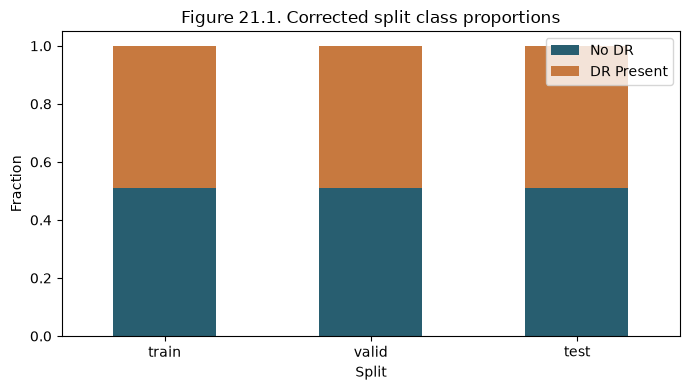

In [5]:
fractions = counts[["No DR", "DR Present"]].div(counts["total"], axis=0)
ax = fractions.plot.bar(stacked=True, color=["#285e70", "#c7793f"], figsize=(7, 4))
ax.set(title="Figure 21.1. Corrected split class proportions", xlabel="Split", ylabel="Fraction")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(output_dir / "figure_21_1_binary_split_distribution.png", dpi=200)
plt.show()


**Table 21.3. All quarantined records**

These binary-label contradictions are not resolved by guessing a label or consulting model predictions. Original files remain unchanged.


In [6]:
quarantine = pd.read_csv(split_dir / "quarantined.csv")
quarantine[["id_code", "split", "diagnosis", "pixel_sha256", "reason"]].to_csv(output_dir / "table_21_3_quarantined_records.csv", index=False)
display(quarantine[["id_code", "split", "diagnosis", "reason"]])


,id_code,split,diagnosis,reason
0,1c9c583c10bf,train,0,identical_pixels_with_conflicting_binary_labels
1,278aa860dffd,train,1,identical_pixels_with_conflicting_binary_labels
2,30cab14951ac,train,1,identical_pixels_with_conflicting_binary_labels
3,42985aa2e32f,train,0,identical_pixels_with_conflicting_binary_labels
4,6165081b9021,train,1,identical_pixels_with_conflicting_binary_labels
5,c546670d9684,train,0,identical_pixels_with_conflicting_binary_labels
6,ea15a290eb96,test,1,identical_pixels_with_conflicting_binary_labels
7,f066db7a2efe,test,0,identical_pixels_with_conflicting_binary_labels


**Table 21.4. Independent cross-split checks**

The check below recomputes all retained candidate pairs rather than relying only on the exported edge list. Zero matches at the selected cutoff does not guarantee absence of other near-duplicates.


In [7]:
from dr_detection.audit import similar_pairs

cross_candidates = similar_pairs(manifest)
exact_cross = int(manifest.groupby("pixel_sha256")["split"].nunique().gt(1).sum())
group_cross = int(manifest.groupby("group_id")["split"].nunique().gt(1).sum())
checks = pd.DataFrame([
    ("Exact RGB groups spanning splits", exact_cross),
    ("Similarity components spanning splits", group_cross),
    ("Recomputed cross-split pHash candidates (distance <= 4)", len(cross_candidates)),
], columns=["check", "count"])
assert checks["count"].eq(0).all(), "The split has a content overlap."
checks.to_csv(output_dir / "table_21_4_independent_overlap_checks.csv", index=False)
display(checks)


,check,count
0,Exact RGB groups spanning splits,0
1,Similarity components spanning splits,0
2,Recomputed cross-split pHash candidates (dista...,0


**Image 21.1. All four quarantined contradictory-label groups**


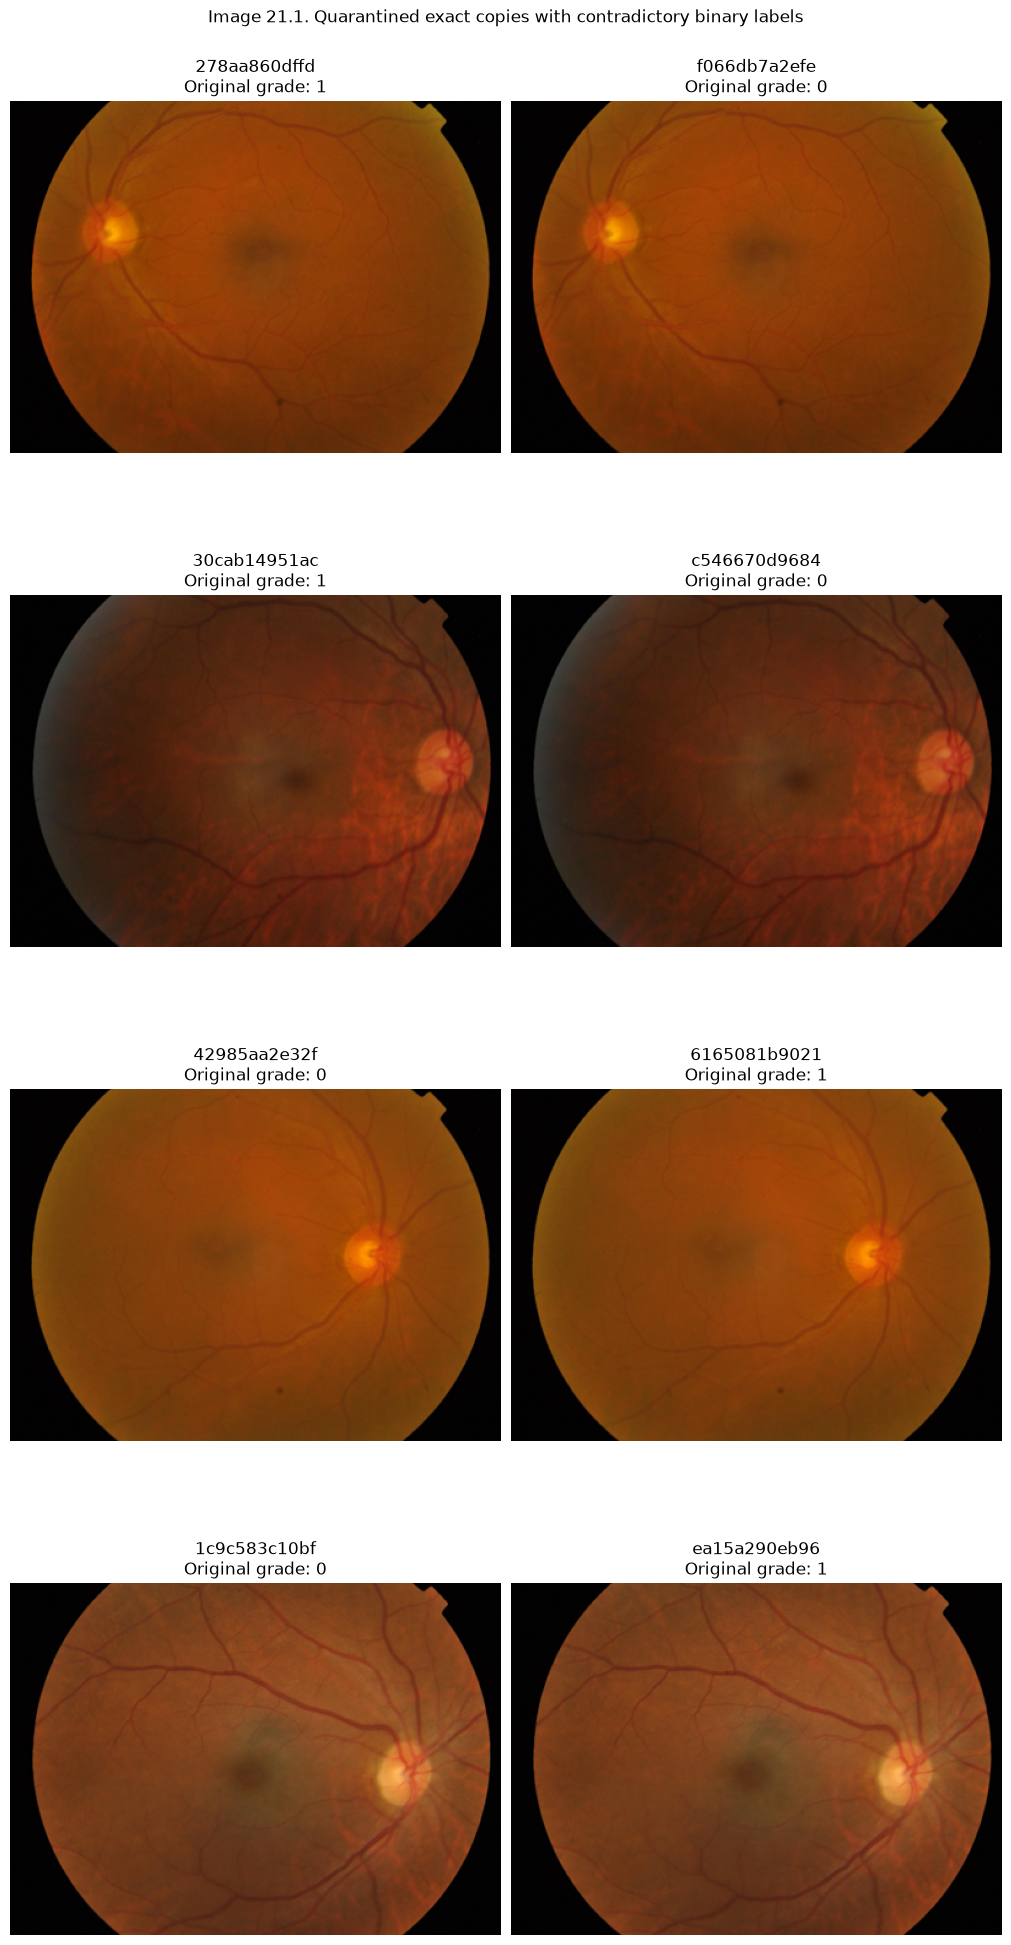

In [8]:
from PIL import Image
groups = list(quarantine.groupby("pixel_sha256", sort=True))
fig, axes = plt.subplots(len(groups), 2, figsize=(10, 5 * len(groups)), squeeze=False, layout="constrained")
for row_axes, (_, group) in zip(axes, groups):
    for ax, row in zip(row_axes, group.itertuples()):
        with Image.open(project_root / row.image_path) as im:
            preview = im.convert("RGB")
            preview.thumbnail((400, 400))
            ax.imshow(preview)
        ax.set_title(f"{row.id_code}\nOriginal grade: {row.diagnosis}")
        ax.axis("off")
fig.suptitle("Image 21.1. Quarantined exact copies with contradictory binary labels")
fig.savefig(output_dir / "image_21_1_quarantined_groups.png", dpi=150)
plt.show()


## Scope and next notebook

Only binary conflicts cause quarantine. Exact copies with different positive severity grades remain compatible with the binary task; their original grades are retained in `original_grades`. This split must not be treated as an adjudicated five-class dataset.

Large similarity components can contain unrelated images, and visual similarity does not identify a patient. Candidate pairs are kept together without deleting images on similarity alone. Image counts are approximately 80/10/10; grouped stratification does not promise exact ratios.

Training is fixed at five epochs with the original B0 preprocessing and optimizer settings. The best epoch is chosen by validation F1, using the earliest epoch for ties. Test evaluation is deferred until training has finished. Continue with notebook 22 to view the frozen results.

Reference: [StratifiedGroupKFold documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html).
